# Cinq graphiques, un seul jeu de données
Population totale de la France par recensement, 1836-1906.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.collections import LineCollection

## Chargement et nettoyage des données

In [13]:
df = pd.read_csv("df_long.csv")

# doublons exacts + valeurs manquantes + doublons partiels (on garde le max)
df = df.drop_duplicates()
df = df.dropna(subset=["population"])
df = (
    df.groupby(["Nom de l'unité d'analyse", "année"], as_index=False)["population"]
    .max()
)

totaux = df.groupby("année")["population"].sum().sort_index()

YEARS = totaux.index.to_numpy()
POP = totaux.to_numpy()

totaux

année
1836    33540910.0
1841    34230178.0
1846    35400486.0
1851    35792170.0
1861    36649609.0
1866    37323315.0
1891    36358462.0
1896    36520168.0
1901    36908852.0
1906    37124441.0
Name: population, dtype: float64

In [14]:
def millions(x, pos):
    return f"{x / 1e6:.0f} M"

## Fonctions utilitaires pour les dégradés de couleur

In [15]:
cmap_rg = plt.matplotlib.colors.LinearSegmentedColormap.from_list(
    "rouge_jaune_vert", ["#DC2626", "#FACC15", "#16A34A"]
)

def colors_from_values(values, cmap=cmap_rg):
    norm = plt.Normalize(vmin=values.min(), vmax=values.max())
    return cmap(norm(values))

def plot_gradient_line(ax, x_pos, values, cmap=cmap_rg, linewidth=3, markersize=8):
    """Trace une courbe dont la couleur, à chaque segment, dépend de la valeur."""
    points = np.array([x_pos, values]).T.reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    norm = plt.Normalize(vmin=values.min(), vmax=values.max())
    # couleur de chaque segment = moyenne des deux valeurs qu'il relie
    seg_values = values[1:]
    lc = LineCollection(segments, cmap=cmap, norm=norm, linewidth=linewidth)
    lc.set_array(seg_values)
    ax.add_collection(lc)
    ax.scatter(x_pos, values, c=values, cmap=cmap, norm=norm, s=markersize**2, zorder=3, edgecolor='white', linewidth=0.8)
    ax.set_xlim(min(x_pos) - 0.3, max(x_pos) + 0.3)

## 1. Croissance spectaculaire
Axe Y tronqué (ne démarre pas à zéro). Couleur des barres : dégradé rouge (valeur basse) → vert (valeur haute).

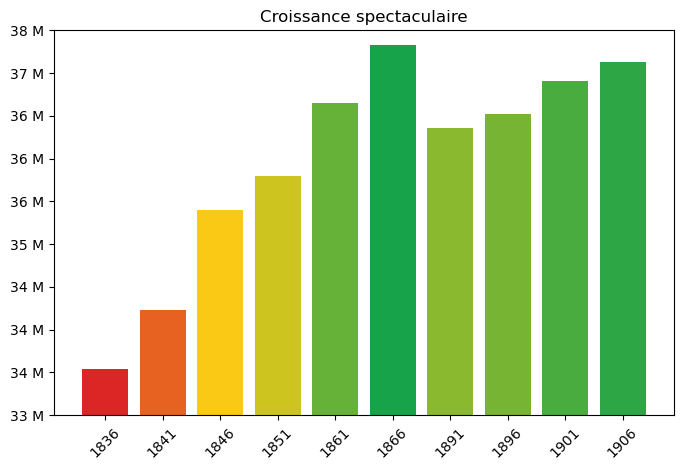

In [16]:
fig, ax = plt.subplots(figsize=(8, 5))
colors = colors_from_values(POP)
ax.bar([str(y) for y in YEARS], POP, color=colors)
ax.set_ylim(33_000_000, 37_500_000)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(millions))
ax.set_title("Croissance spectaculaire")
plt.xticks(rotation=45)
plt.show()

## 2. Déclin alarmant
Cherry-picking sur 1861-1891, axe Y tronqué. Couleur de la courbe : dégradé rouge → vert selon la valeur.

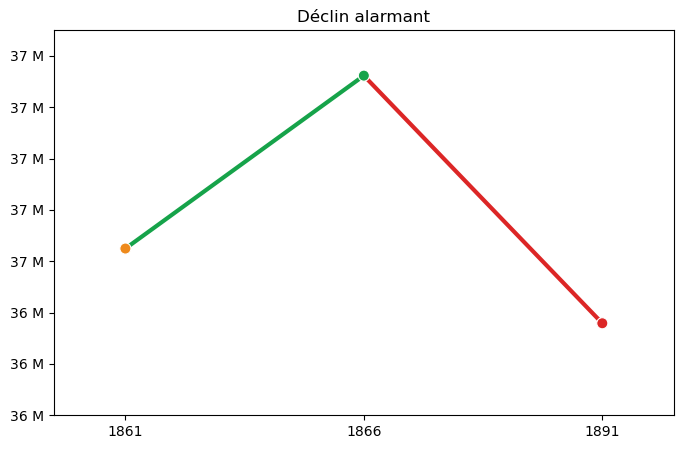

In [17]:
mask = (YEARS >= 1861) & (YEARS <= 1891)
sub_years, sub_pop = YEARS[mask], POP[mask]
x_pos = np.arange(len(sub_years))

fig, ax = plt.subplots(figsize=(8, 5))
plot_gradient_line(ax, x_pos, sub_pop)
ax.set_xticks(x_pos)
ax.set_xticklabels([str(y) for y in sub_years])
ax.set_ylim(36_000_000, 37_500_000)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(millions))
ax.set_title("Déclin alarmant")
plt.show()

## 3. Stagnation totale
Axe Y correct (part de zéro), mais années à intervalles égaux (masque le vide 1866-1891). Couleur : jaune.

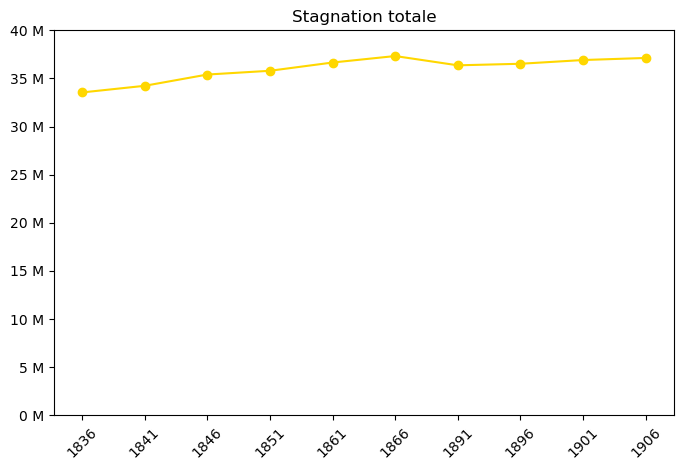

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot([str(y) for y in YEARS], POP, marker="o", color="gold")
ax.set_ylim(0, 40_000_000)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(millions))
ax.set_title("Stagnation totale")
plt.xticks(rotation=45)
plt.show()

## 4. Reprise triomphale
Cherry-picking sur 1891-1906, axe Y tronqué. Couleur des barres : dégradé rouge → vert selon la valeur.

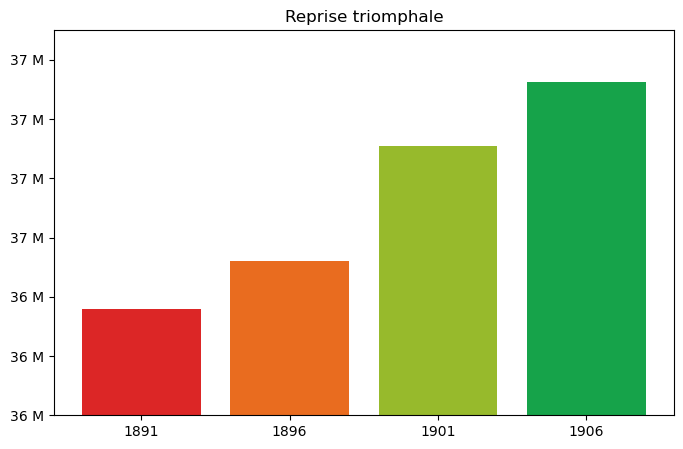

In [19]:
mask = YEARS >= 1891
sub_years, sub_pop = YEARS[mask], POP[mask]

fig, ax = plt.subplots(figsize=(8, 5))
colors = colors_from_values(sub_pop)
ax.bar([str(y) for y in sub_years], sub_pop, color=colors)
ax.set_ylim(36_000_000, 37_300_000)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(millions))
ax.set_title("Reprise triomphale")
plt.show()

## 5. Version honnête
Période complète, axe X en échelle temporelle réelle, axe Y à zéro.

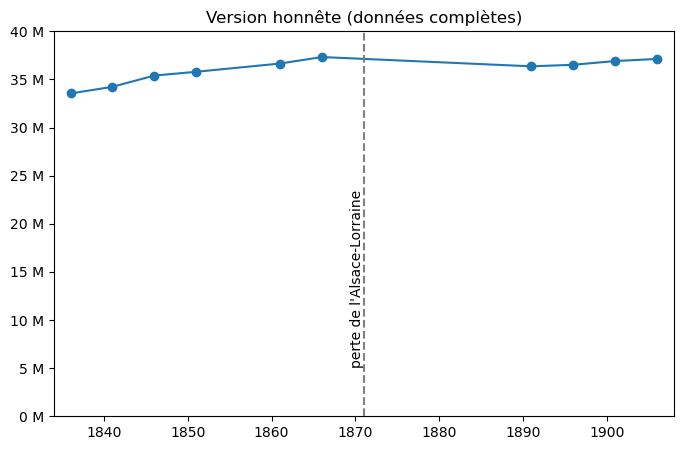

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(YEARS, POP, marker="o")
ax.set_ylim(0, 40_000_000)
ax.set_xlim(1834, 1908)
ax.axvline(1871, linestyle="--", color="gray")
ax.annotate("perte de l'Alsace-Lorraine", xy=(1871, 5_000_000), rotation=90, va="bottom", ha="right")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(millions))
ax.set_title("Version honnête (données complètes)")
plt.show()